<a href="https://colab.research.google.com/github/chandumonubol/DeepLearning-and-Neural-Network/blob/main/RNN_Case2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on: News Article Classification Using RNN

## Problem Statement

An online news platform publishes articles related to different topics such as business, politics, sports, and technology. Manually categorizing thousands of news articles can be time-consuming. Your task is to develop a **Recurrent Neural Network (RNN) model** that automatically identifies the category of a news article based on its content.

## 1. Dataset Description

For this experiment, use the **Reuters Newswire Dataset** available in TensorFlow/Keras.

- **Total articles:** 11,228
- **Training articles:** 8,982
- **Testing articles:** 2,246
- **Number of categories:** 46
- **Vocabulary size:** Top 10,000 most frequent words.
- Each article is represented as a sequence of numerical word IDs.
- Each article has a corresponding category label ranging from 0 to 45.

**Note:** The dataset is already preprocessed into numerical sequences. Manual tokenization and numerical encoding are not required.

## 2. Tasks to Perform

1. Load the Reuters dataset and explore its structure.
2. Display the number of training and testing articles.
3. Display a sample news article, its category label, and its sequence length.
4. Understand why news articles have different sequence lengths and why padding is required.
5. Apply padding to make all articles a fixed length of 200 using post-padding and post-truncation.
6. Build an RNN model using an **Embedding layer**, **SimpleRNN layer**, and **Dense output layer**.
7. Output layer
8. Compile the model
9. Train the model
10. Evaluate the model using the testing dataset and visualize training and validation accuracy.

## 3. Import the Required Libraries

```python
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import reuters
```

## 4. Load the Dataset

```python
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = reuters.load_data(
    num_words=vocab_size
)
```

```

## 4. Expected Outcome

Build and evaluate a Simple RNN model that automatically classifies news articles into one of the 46 available categories based on their content.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import reuters

In [ ]:
vocab_size = 10000

(X_train, y_train), (X_test, y_test) = reuters.load_data(
    num_words=vocab_size
)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#explore the dataset

print("training reviews: ",len(X_train))
print("testing reviews: ",len(X_test))

print("first review is : ", X_train[0])
print("Label of first review is : ", y_train[0])

training reviews:  8982
testing reviews:  2246
first review is :  [1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 3095, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 4579, 1005, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 1245, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]
Label of first review is :  3


In [ ]:
#padding
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
max_length = 200

X_train = pad_sequences(X_train, maxlen = max_length,padding = "post",truncating= 'post' )
X_test = pad_sequences(X_test, maxlen = max_length,padding = "post" , truncating= 'post')

In [ ]:
print(X_train.shape)
print(X_test.shape)

(8982, 200)
(2246, 200)


In [ ]:
#Build the RNN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

In [ ]:
model = Sequential([
    Embedding(input_dim=10000, output_dim=32, mask_zero=True),
    SimpleRNN(32),
    Dense(46, activation='softmax')  # Changed from Dense(1, activation='sigmoid')
])

In [ ]:
model.compile(optimizer= 'adam',loss = 'sparse_categorical_crossentropy',metrics = ['accuracy'])

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs = 5,
    batch_size = 128,
    validation_split = 0.2
)#i first did epochs 5, then 10, then 5 and again 5 then i got this accurecy

Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - accuracy: 0.8958 - loss: 0.4452 - val_accuracy: 0.3840 - val_loss: 3.0493
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - accuracy: 0.9009 - loss: 0.4237 - val_accuracy: 0.3817 - val_loss: 3.1983
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 11s 121ms/step - accuracy: 0.9051 - loss: 0.3978 - val_accuracy: 0.3851 - val_loss: 3.1820
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9073 - loss: 0.3974 - val_accuracy: 0.3845 - val_loss: 3.2552
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - accuracy: 0.9150 - loss: 0.3672 - val_accuracy: 0.3862 - val_loss: 3.2138


In [ ]:
#evaluate
test_loss,test_accuracy = model.evaluate(X_test,y_test)
print(test_loss)
print(test_accuracy)

71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3762 - loss: 3.2505
3.250502824783325
0.3762243986129761


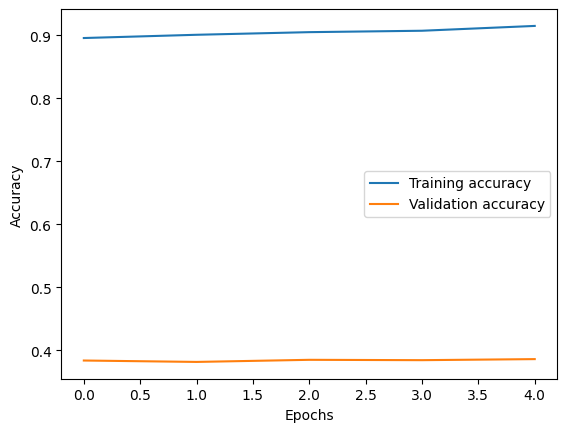

In [ ]:
#visualize
plt.plot(history.history['accuracy'],label = "Training accuracy")
plt.plot(history.history['val_accuracy'],label = 'Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

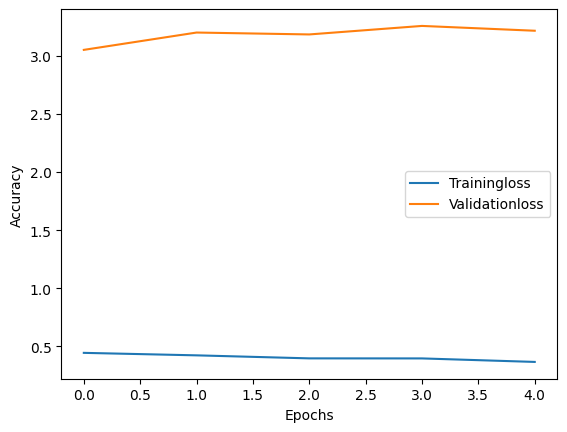

In [ ]:
#visualize
plt.plot(history.history['loss'],label = "Trainingloss")
plt.plot(history.history['val_loss'],label = 'Validationloss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
model2 = Sequential([
    Embedding(input_dim=10000, output_dim=64, mask_zero=True),
    SimpleRNN(64, return_sequences=True),  # Return sequences for the next RNN layer
    SimpleRNN(32),
    Dense(46, activation='softmax')
])

In [ ]:
model2 = Sequential([
    Embedding(input_dim=10000, output_dim=64, mask_zero=True),
    SimpleRNN(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(46, activation='softmax')
])

In [ ]:
model2.compile(optimizer= 'adam',loss = 'sparse_categorical_crossentropy',metrics = ['accuracy'])

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,          # Stop if val_loss doesn't improve for 3 consecutive epochs
    restore_best_weights=True
)

history2 = model2.fit(
    X_train,
    y_train,
    epochs=15,           # Can set higher since early stopping will halt it safely
    batch_size=64,       # Smaller batch size often helps gradient updates for text
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 124ms/step - accuracy: 0.2543 - loss: 2.9513 - val_accuracy: 0.3450 - val_loss: 2.3885
Epoch 2/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.3418 - loss: 2.4654 - val_accuracy: 0.3472 - val_loss: 2.3659
Epoch 3/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 14s 121ms/step - accuracy: 0.3496 - loss: 2.4267 - val_accuracy: 0.3561 - val_loss: 2.3445
Epoch 4/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.3530 - loss: 2.3874 - val_accuracy: 0.3550 - val_loss: 2.3080
Epoch 5/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 14s 122ms/step - accuracy: 0.3678 - loss: 2.3294 - val_accuracy: 0.3656 - val_loss: 2.2453
Epoch 6/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 20s 120ms/step - accuracy: 0.3886 - loss: 2.2480 - val_accuracy: 0.3856 - val_loss: 2.1957
Epoch 7/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 121ms/step - accuracy: 0.4224 - loss: 2.1673 - val_accuracy: 0.3990 - val_loss: 2.1960
Epoch 8/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 20s 121ms/step - accuracy: 0.4340 - loss: 2